In [13]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/29/2022
# version ='1.0'

# Demo: Further Experiments on Solving A Family of LP by Barrier Method

In book-convex-2004, the barrier method was used to solve the standard form linear programming problem

\begin{equation}
\begin{array}{rcl}
\text{minimize} & c^T x \\
\text{subject to} & Ax = b & x\succeq 0 \\
\end{array}
\end{equation}

with $A\in R^{m\times n}$. Its centering problem is
\begin{equation}
\begin{array}{rcl}
\text{minimize} & tc^Tx-\displaystyle{\sum_{i=1}^n}\log x_i \\
\text{subject to} & Ax = b \\
\end{array}
\end{equation}

The method to construct the parameter $A, b, c$ has been described in another article. 

As described in the section 11.8.1, block elimination can be used to solve the Newton equations given by

$$
\begin{array}{rcccl}
\left[\begin{array}{cc}
diag(x)^{-2} & A^T \\
A & 0 \\
\end{array} \right] & \left[
\begin{array}{c}
\Delta x_{nt} \\
\nu_{nt} \\
\end{array}
\right] & = & \left[
\begin{array}{c}
-tc + diag(x)^{-1}\mathbf{1} \\
0 \\
\end{array}
\right]
\end{array}
$$

In the block elimination, it first solves the $\nu_{nt}$ and then $\Delta x_{nt}$ by the following step,

\begin{equation}
\begin{array}{rcl}
A diag(x)^2 A^T\nu_{nt} & = & -tAdiag(x)^2c+b \\
\Delta x_{nt} & = & -tdiag(x)^2c+x-diag(x)^2A^T\nu_{nt} \\
\end{array}
\end{equation}
where the following equation can be solved by Cholesky factorization using scipy.linalg.cho\_factor and scipy.linalg.cho\_solve.


However, in the experiment, it is also found that, when using the block elimination by first getting $\nu_{nt}$ and then getting $\Delta x_{nt}$, it may be that the numerical errors in $A\Delta x_{nt}=0$ becomes much larger, which may lead to non-convergence in the centering step in the barrier method. A trick here is, when $A\Delta x_{nt}>0$ after the block elimination algorithm, then $x_{nt}$ will be recalculated by the direct inversion again. However, this trick does not solve the problem completely because, even using the direct matrix inversion, it is still possible that the numerical loss will lead to $A\Delta x_{nt}>0$. In this case, the primal-dual interior method is preferred for this better numerical robustness.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from scipy.linalg import cho_factor, cho_solve
import time

 $f_0(x)=c^Tx$
 
 $\nabla f_0(x)=c$
 
 $\nabla^2 f_0(x)=0$

In [15]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-1\sum \log x_i$

$\nabla \phi(x)=\dfrac{-1}{x}$

$\nabla^2 \phi(x)=\dfrac{1}{x^2}$

In [16]:
def my_phi(x, t, A, b, c):
    """
    $\phi(x)=-1\sum \log x_i$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 * np.sum(np.log(x))


def my_phi_feasible(x, t, A, b, c):
    return np.all(x > 0)


def my_gradient_phi(x, t, A, b, c):
    """
    $\nabla \phi(x)=\dfrac{-1}{x}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 / x


def my_hessian_phi(x, t, A, b, c):
    """
    $\nabla^2 \phi(x)=\dfrac{1}{x^2}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.diag(np.squeeze(1 / (x ** 2)))

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [17]:
def my_f(x, t, A, b, c):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_f_0(x, t, A, b, c) + my_phi(x, t, A, b, c)


def my_f_feasible(x, t, A, b, c):
    return my_f_0_feasible(x, t, A, b, c) and my_phi_feasible(x, t, A, b, c)


def my_gradient_f(x, t, A, b, c):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_gradient_f_0(x, t, A, b, c) + my_gradient_phi(x, t, A, b, c)


def my_hessian_f(x, t, A, b, c):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_hessian_f_0(x, t, A, b, c) + my_hessian_phi(x, t, A, b, c)

Calculation of the Newton step by using cholesky: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

Note: A trick here is, when $A\Delta x_{nt}>0$ after the block elimination algorithm, then $x_{nt}$
    will be recalculated by the direct inversion again. However, this trick does not solve the problem completely
    because, even using the direct matrix inversion, it is still possible that the numerical loss will lead to
    $A\Delta x_{nt}>0$.
    In this case, the primal-dual interior method is preferred for this better numerical robustness.

In [18]:
def my_newton_step_decrement_cholesky(x, args):
    """
    Calculation of the Newton step by using cholesky: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    Note: A trick here is, when $A\Delta x_{nt}>0$ after the block elimination algorithm, then $x_{nt}$
    will be recalculated by the direct inversion again. However, this trick does not solve the problem completely
    because, even using the direct matrix inversion, it is still possible that the numerical loss will lead to
    $A\Delta x_{nt}>0$.
    In this case, the primal-dual interior method is preferred for this better numerical robustness.
    :param x:
    :param args:
    :return:
    """
    (t, A, b, c) = args

    H = A @ np.diag(np.squeeze(x) ** 2) @ A.T
    g = -t * (A @ np.diag(np.squeeze(x) ** 2) @ c) + b

    cholesky_c, cholesky_low = cho_factor(H)
    nu_nt = np.reshape(cho_solve((cholesky_c, cholesky_low), np.squeeze(g)), (-1, 1))

    x_nt = -t * (np.diag(np.squeeze(x) ** 2) @ c) + x - np.diag(np.squeeze(x) ** 2) @ A.T @ nu_nt

    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    decrement_1 = -1 * gradient.T @ x_nt
    decrement_2 = x_nt.T @ hessian @ x_nt
    # for debug purpose
    # Axnt = np.allclose(A @ x_nt, 0)
    # Axb = np.allclose(A @ x, b)
    # if Axnt:
    #     print('DBG: t={}, A x_nt == 0'.format(t))
    # else:
    #     print('DBG: t={}, A x_nt != 0'.format(t))
    # if Axb:
    #     print('DBG: t={}, A x = b'.format(t))
    # else:
    #     print('DBG: t={}, A x != b'.format(t))
    # if not np.allclose(decrement_1, decrement_2):
    #     print('Warning: Quantization error detected in the two ways in calculating the decrement')
    # if decrement_1 < 0:
    #     print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

    if decrement_1 < 0:
        # print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction, '
        #      'fall back to direct inversion.')
        return my_newton_step_decrement_direct_inverse(x, args)

    decrement = decrement_2
    return x_nt, decrement.item()

Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [19]:
def my_newton_step_decrement_direct_inverse(x, args):
    """
    Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param args:
    :return:
    """
    (t, A, b, c) = args
    (m, n) = A.shape
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = np.block([[hessian, A.T], [A, np.zeros((m, m))]])
    residual = np.block([[gradient], [np.zeros((m, 1))]])
    cond = np.linalg.cond(KKT)
    # relax the condition number to be as large as 1e30 in this family of LP problems
    # refer to the FlexibleLecture note
    if cond < 1e30:
        x_nt_w = np.linalg.inv(KKT) @ (-1 * residual)
        x_nt = x_nt_w[0: n]
        decrement = x_nt.T @ hessian @ x_nt
        # decrement_1 = -1 * gradient.T @ x_nt
        # if decrement_1 < 0:
        #     print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invisible')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [20]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
$\alpha$, $\beta$ in the backtracking line search method.

In [21]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, A, b, c, cholesky=True, max_newton_iteration=100):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param cholesky:
    :param max_newton_iteration:
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    x = x0
    args = (barrier_t, A, b, c)
    if cholesky:
        x_nt, decrement = my_newton_step_decrement_cholesky(x, args)
    else:
        x_nt, decrement = my_newton_step_decrement_direct_inverse(x, args)

    iteration = 1  # a Newton iteration has been executed
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        # print(r'Info: iteration={}, decrement={}, t={}'.format(iteration, decrement, t))
        x = x + t * x_nt
        if cholesky:
            x_nt, decrement = my_newton_step_decrement_cholesky(x, args)
        else:
            x_nt, decrement = my_newton_step_decrement_direct_inverse(x, args)

        iteration = iteration + 1
        if iteration > max_newton_iteration:
            #print('Error: Newton method not converged!')
            break

    # print(r'Info: iteration={}, decrement={}'.format(iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, None, None, None

A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
    with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$

In [22]:
def get_A_b_c(m, n, l):
    """
    A revised Method to generate parameters $(A, b, c)$ and initial starting point $x_0$,
    with a unique optimal point, and bounded feasible set $\{x|Ax=b,x\succeq 0, rank(A)=m\}$
    :param m:
    :param n:
    :param l:
    :return:
    """
    if n != 2 * m:
        raise RuntimeError('currently only support n = 2m scenarios')

    x_asterisk = np.random.uniform(low=0, high=1, size=(n, 1))
    x_asterisk[0:l] = 0
    lambda_ = np.random.uniform(low=0, high=1, size=(n, 1))
    lambda_[l:] = 0

    B = np.zeros((n, n - l))
    E = np.zeros((n, n - l))
    for li in range(n - l):
        xe = x_asterisk.copy()
        xe[0:l] = np.random.uniform(low=0, high=1, size=(l, 1))
        xe[l + li] = 0.5 * x_asterisk[l + li]  # $x_{e,i}$
        dx = xe - x_asterisk  # $d_i=x_{e,i}-x^*$
        B[:, li] = np.squeeze(dx)
        E[:, li] = np.squeeze(xe)

    x0 = np.reshape(np.average(E, axis=1), (-1, 1))  # $x_0=\dfrac{1}{n-l}\displaystyle{\sum_{i=1}^{n-l}}(x_{e,i})$

    Ns_B = null_space(B.T)
    A = Ns_B[:, 0:m].T  # only the first m is selected if n=2m

    b1 = A @ x0
    b2 = A @ x_asterisk
    if not np.allclose(b1, b2):
        raise RuntimeError('x0, xp should both satisfy Ax = b')
    b = b1

    nu = np.random.normal(loc=0, scale=1, size=(m, 1))
    c = lambda_ - A.T @ nu

    return A, b, c, x_asterisk, x0, nu

plot the convergence of the barrier method versus m in ms

In [23]:
def solve_LP_by_barrier_method(seed, mu, ms, cholesky=True):
    """
    plot the convergence of the barrier method versus m in ms
    :param cholesky:
    :param seed:
    :param mu:
    :return:
    """
    m_s = ms
    for m_i, m in enumerate(m_s):
        n = 2 * m
        np.random.seed(seed)
        if m > n:
            raise RuntimeError('it requires m > n')

        l = n - m
        A, b, c, x_asterisk, x0, nu = get_A_b_c(m, n, l)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-5
        duality_gap_epsilon = n * 1e-6
        t0 = 1
        t = t0

        # run centering step once to ensure that the initial point is on the central path with t_0 = 1
        args = (t, A, b, c)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args, cholesky=cholesky)
        x0 = xt
        t = mu * t

        while True:
            args = (t, A, b, c)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args, cholesky=cholesky)
            x0 = xt
            if m / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

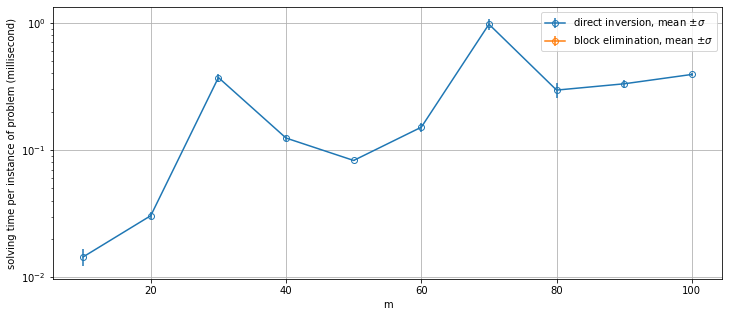

In [24]:
if __name__ == "__main__":
    n_dial = 3
    m_s = [10 * i for i in range(1, 11)]
    run_time_inv = np.zeros((len(m_s), n_dial))
    run_time_cholesky = np.zeros((len(m_s), n_dial))
    for mi, m in enumerate(m_s):
        for dial in range(n_dial):
            start = time.time()
            solve_LP_by_barrier_method(seed=1, mu=50, ms=[m], cholesky=False)
            end = time.time()
            run_time_inv[mi][dial] = end - start
            #print("Info: m={}, dial={}: Runtime of the program inv is {}".format(m, dial, end - start))
            start = time.time()
            solve_LP_by_barrier_method(seed=1, mu=50, ms=[m], cholesky=True)
            end = time.time()
            #run_time_cholesky[mi][dial] = end - start
            #print("Info: m={}, dial={}: Runtime of the program cholesky is {}".format(m, dial, end - start))

    plt.figure(figsize=(12, 5))
    ax = plt.subplot(1, 1, 1)
    avg_num_iter = np.average(run_time_inv, axis=1)
    std_num_iter = np.std(run_time_inv, axis=1)
    plt.errorbar(m_s, avg_num_iter, yerr=std_num_iter, marker='o', fillstyle='none',
                 label=r'direct inversion, mean $\pm \sigma$')

    avg_num_iter = np.average(run_time_cholesky, axis=1)
    std_num_iter = np.std(run_time_cholesky, axis=1)

    plt.errorbar(m_s, avg_num_iter, yerr=std_num_iter, marker='o', fillstyle='none',
                 label=r'block elimination, mean $\pm \sigma$')
    ax.set_yscale('log')
    ax.set_xlabel(r'm')
    ax.set_ylabel(r'solving time per instance of problem (millisecond)')
    ax.grid()
    plt.legend()
    plt.show()